# 09 – Régression linéaire : allergies (baseline)

Cible : TousAge_allergie_urgences, le taux de passages aux urgences pour allergie, tous âges, par semaine et par département.

On compare une régression linéaire à deux prédictions très simples (les baselines). Si la régression ne fait pas mieux qu'elles, elle n'apporte rien.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

## 1. Les données

In [2]:
# fichier fusionné par le groupe (07_Merge)
df = pd.read_csv('../data/final_metropole/Merge_final.csv', dtype={'code_dept': str})

# année et numéro de semaine, '2021-S01'
df['annee'] = df['date_semaine'].str[:4].astype(int)
df['semaine'] = df['date_semaine'].str[-2:].astype(int)
# blocs de 4 semaines (≈ un mois) : 0, 1, 2 ... 12
df["periode"] = (df["semaine"] - 1) // 4

# une colonne 0/1 par bloc
dummies = pd.get_dummies(df["periode"], prefix="periode")

# on retire un bloc : il se déduit des autres
dummies = dummies.drop(columns="periode_0")
df = df.join(dummies)

cible = 'TousAge_allergie_urgences'

print(df.shape)
df[cible].describe()

(19968, 91)


count    19968.000000
mean       744.778217
std        315.852165
min          0.000000
25%        538.838945
50%        699.809373
75%        900.156926
max       3636.363636
Name: TousAge_allergie_urgences, dtype: float64

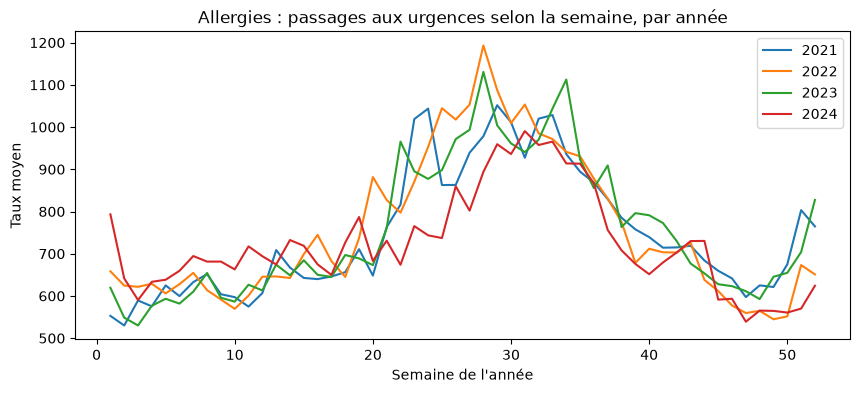

In [3]:
plt.figure(figsize=(10, 4))

# une courbe par année
for annee in [2021, 2022, 2023, 2024]:
    donnees = df[df['annee'] == annee]
    moy = donnees.groupby('semaine')[cible].mean()
    plt.plot(moy.index, moy.values, label=str(annee))

plt.xlabel('Semaine de l\'année')
plt.ylabel('Taux moyen')
plt.title('Allergies : passages aux urgences selon la semaine, par année')
plt.legend()
plt.show()

Les passages aux urgences pour allergie augmentent à partir du printemps et sont les plus hauts en été, puis redescendent à l'automne. Les 4 années ont la même saisonnalité. 2024 se distingue par un pic estival plus faible et tardif.

## 2. Découpage train / test 

On entraîne sur 2021-2023 et on teste sur 2024. 

In [4]:
train = df[df['annee'] <= 2023]
test = df[df['annee'] == 2024]

print(train.shape, test.shape)

(14976, 91) (4992, 91)


## 3. Les baselines

Baseline 1 : on prédit toujours la moyenne de 2021-2023(dep,années et sem confondus).

Baseline 2 : pour chaque département et chaque semaine, on prédit la moyenne des mêmes semaines en 2021-2023 (par exemple, l'Ain semaine 28 de 2024 = moyenne de l'Ain semaine 28 en 2021, 2022 et 2023).

In [5]:
def scores(nom, reel, predit):
    print(nom)
    print('RMSE :', np.sqrt(mean_squared_error(reel, predit)))
    print('R² :', r2_score(reel, predit))

In [6]:
# baseline 1 : la même valeur partout
moyenne = train[cible].mean()
pred_b1 = [moyenne] * len(test)
scores('Baseline 1 (moyenne)', test[cible], pred_b1)

# baseline 2 : moyenne par département et par semaine, calculée sur le train
moy_dep_sem = train.groupby(['code_dept', 'semaine'])[cible].mean()
moy_dep_sem = moy_dep_sem.reset_index()
moy_dep_sem.columns = ['code_dept', 'semaine', 'pred_b2']

# on colle cette moyenne à chaque ligne de 2024
test_b2 = pd.merge(test, moy_dep_sem, on=['code_dept', 'semaine'], how='left')
scores('Baseline 2 (même semaine)', test_b2[cible], test_b2['pred_b2'])

Baseline 1 (moyenne)
RMSE : 294.2844527196708
R² : -0.008314373769412908
Baseline 2 (même semaine)
RMSE : 267.93928748847804
R² : 0.16413889385401803


## 4. Régression linéaire

Variables utilisées :
- pollution (5 métaux dans les PM10) ;
- météo ;
- socio-économiques (sans les artisans : les 8 CSP font 100 % ensemble, on en retire une pour une régression linéaire).

On n'utilise pas les autres colonnes santé (asthme, bronchiolite, hospitalisations, classes d'âge) : ce sont d'autres cibles, ou des morceaux de notre cible.

In [7]:
pollution = ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10']

meteo = ['pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse',
         'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station',
         'periode_rafale', 'precipitation_1h', 'precipitation_3h', 'precipitation_6h',
         'precipitation_12h', 'precipitation_24h', 'tp_averses_ou_orages', 'tp_brouillard',
         'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide',
         'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine',
         'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige',
         'tp_temps_inconnu']

socio = ['pct_urbain', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers',
         'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs',
         'densite_generalistes', 'densite_pediatres', 'densite_pneumologues',
         'densite_allergologues', 'densite_kines', 'sos_present']

periode = list(dummies.columns)

variables = pollution + meteo + socio + periode

# astype(float) : sos_present (True / False) devient 1 / 0
X_train = train[variables].astype(float)
X_test = test[variables].astype(float)
y_train = train[cible]
y_test = test[cible]

In [8]:
# standardisation : fit sur le train seulement
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

pred_train = lr.predict(X_train_scaled)
pred_test = lr.predict(X_test_scaled)

scores('Régression - train', y_train, pred_train)
scores('Régression - test ', y_test, pred_test)

Régression - train
RMSE : 265.0059745107137
R² : 0.32603727510776803
Régression - test 
RMSE : 259.13599082551184
R² : 0.21816196942212063


## 5. Prédit contre réel (2024)

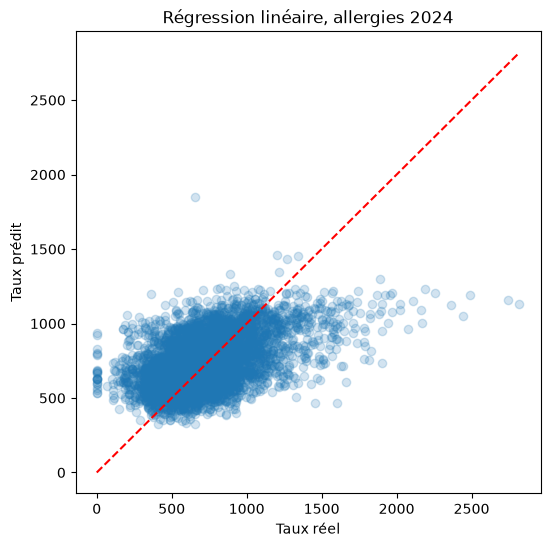

In [9]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_test, alpha=0.2)
# ligne rouge : prédiction parfaite
maxi = max(y_test.max(), pred_test.max())
plt.plot([0, maxi], [0, maxi], color='red', linestyle='--')
plt.xlabel('Taux réel')
plt.ylabel('Taux prédit')
plt.title('Régression linéaire, allergies 2024')
plt.show()

## 6. Les variables qui pèsent le plus

In [10]:
# données standardisées : on peut comparer la taille des coefficients
coefs = pd.Series(lr.coef_, index=variables)
coefs = coefs.sort_values(key=abs, ascending=False)
coefs.head(10).round(1)

pct_retraites           280.5
pct_cadres              241.7
pct_sans_activite       142.2
pct_urbain             -117.4
pct_ouvriers            109.3
pct_employes            101.4
temperature_kelvin       85.6
pct_prof_inter           68.3
densite_generalistes    -60.5
periode_6                52.2
dtype: float64

La régression linéaire fait un peu mieux que les baselines, mais le modèle reste trop simple : sur le graphique : ne suit pas la distribution réelle 

Coefficients. Les CSP arrivent en premier, mais on ne peut pas les interpréter : elles sont très liées entre elles et leurs effets se compensent.

météo : plus il fait chaud, plus il y a de passages, et la pluie les diminue: cohérent avec les allergies aux pollens.